# Case Study 14 — Which Acquisition Channel Brings the Most Valuable Customers?

**One-way ANOVA · why not many t-tests · F-statistic and the sum-of-squares decomposition · η² and ω² · checking
assumptions (Levene / Brown-Forsythe, residual Q-Q) · Welch ANOVA · Tukey HSD vs Games-Howell post-hoc tests ·
planned contrasts · ANOVA as regression · ANCOVA: channel effect vs customer mix · value net of acquisition cost**

| | |
|---|---|
| **Domain** | Marketing: credit-card customer acquisition |
| **Stakeholders** | Head of Cards Marketing, Finance business partner |
| **Difficulty** | Intermediate |
| **Importance** | 🟠 SHOULD GO THROUGH |
| **Builds on** | Case 02 (two-group tests), Case 07–08 (regression, confounding) |
| **Data** | 6,000 customers acquired last year through 5 channels; cost per acquisition by channel |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`.

**What you will learn**

1. Why comparing many groups with repeated t-tests inflates false alarms, and what ANOVA does instead.
2. How to read an ANOVA table, the F-statistic and effect sizes (η², ω²).
3. What to do when groups have **unequal variances and sizes** (Welch ANOVA, Games-Howell).
4. How to find **which** groups differ (post-hoc tests) without inflating the error rate.
5. Why "which channel brings the most valuable customers?" and "which channel should get the budget?" have different
   answers.

## Section 1 — Business context

You are a data scientist supporting **Cards Marketing**. Last year the bank acquired about 6,000 credit-card customers
through five channels: **Branch**, **Search ads**, **Social media**, a comparison-site **Aggregator**, and a
**Partner co-brand** with an e-commerce platform. For each customer we know the **first-year net revenue** (interchange,
interest and fees minus rewards and credit losses; it can be negative) and, for each channel, the **cost per
acquisition** (CAC).

The Head of Cards Marketing writes:

> *"The aggregator brings our most valuable customers, so I want to double its budget and cut social media, which
> brings the least valuable. Before I take this to Finance, tell me: do the channels really differ, which ones, by how
> much, and is it the channel or just the kind of customer it attracts?"*

## Section 2 — Business questions

1. Do the five channels differ in first-year net revenue per customer?
2. If so, **which** channels differ from which?
3. How large are the differences, in ₹ and as a share of the variation?
4. Is a channel's value due to the channel, or to the customers it attracts (income)?
5. Where should the next rupee of acquisition budget go?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Do channels differ? | H₀: all five population means equal | One-way ANOVA; Welch ANOVA (unequal variances) |
| 2 | Which ones? | All pairwise differences with family-wise error control | Tukey HSD; Games-Howell |
| 3 | How large? | Effect size and CIs | η², ω²; mean differences with CIs |
| 4 | Channel or mix? | Channel differences at the same income | ANCOVA (regression with channel dummies + log income) |
| 5 | Budget | Net value per customer and per ₹ spent, with uncertainty | Value − CAC; return per ₹ (bootstrap CIs) |

In [1]:
import sys
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_money, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, thousands_formatter, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "14_acquisition_channel_anova"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(1414)
kfmt = thousands_formatter("₹", "k", 1e3, 1)
ORDER = ["Branch", "Search ads", "Social media", "Aggregator", "Partner co-brand"]
CH_COL = dict(zip(ORDER, [COLORS["blue"], COLORS["aqua"], COLORS["magenta"], COLORS["orange"], COLORS["violet"]]))

## Section 4 — Load the data

In [2]:
cust = pd.read_csv(PATHS["data"] / "new_customers.csv")
costs = pd.read_csv(PATHS["data"] / "channel_costs.csv").set_index("channel")["cost_per_acquisition"]
print(f"{cust.shape[0]:,} customers × {cust.shape[1]} columns;  duplicates: {cust['customer_id'].duplicated().sum()};  "
      f"missing: {cust.isna().sum().sum()}")
display(cust.head())
cust["channel"] = pd.Categorical(cust["channel"], categories=ORDER)
cust["log_income"] = np.log(cust["monthly_income"] / 60_000)
display(costs.to_frame("cost per acquisition (₹)"))

6,000 customers × 5 columns;  duplicates: 0;  missing: 0


,customer_id,channel,age,monthly_income,first_year_net_revenue
0,NC14100000,Social media,39,"19,500.0000","2,170.0000"
1,NC14100001,Branch,26,"65,200.0000","5,090.0000"
2,NC14100002,Aggregator,33,"109,300.0000","-1,870.0000"
3,NC14100003,Search ads,32,"57,500.0000","7,180.0000"
4,NC14100004,Partner co-brand,45,"46,000.0000","4,670.0000"


,cost per acquisition (₹)
channel,
Branch,2200
Search ads,1800
Social media,1100
Aggregator,2900
Partner co-brand,900


## Section 5 — Descriptive statistics

In [3]:
y = "first_year_net_revenue"
desc = cust.groupby("channel", observed=True).agg(n=(y, "size"), mean=(y, "mean"), sd=(y, "std"), median=(y, "median"),
                                                  share_negative=(y, lambda s: (s < 0).mean()),
                                                  median_income=("monthly_income", "median"))
desc["se"] = desc["sd"] / np.sqrt(desc["n"])
desc["ci_low"] = desc["mean"] - stats.t.ppf(0.975, desc["n"] - 1) * desc["se"]
desc["ci_high"] = desc["mean"] + stats.t.ppf(0.975, desc["n"] - 1) * desc["se"]
save_table(desc, "channel_summary", PATHS["tables"])
desc

,n,mean,sd,median,share_negative,median_income,se,ci_low,ci_high
channel,,,,,,,,,
Branch,1800,"3,053.7778","3,101.0793","3,145.0000",0.1622,"63,500.0000",73.0931,"2,910.4214","3,197.1342"
Search ads,1500,"3,115.6733","3,365.0117","3,120.0000",0.1720,"66,950.0000",86.8842,"2,945.2458","3,286.1009"
Social media,1200,"2,187.6167","2,944.9127","2,240.0000",0.2217,"49,600.0000",85.0123,"2,020.8272","2,354.4061"
Aggregator,900,"3,309.4111","5,363.7865","3,360.0000",0.2833,"90,500.0000",178.7929,"2,958.5111","3,660.3111"
Partner co-brand,600,"3,045.6667","2,642.3276","3,095.0000",0.1233,"57,100.0000",107.8726,"2,833.8122","3,257.5211"


**Observation.**
- The **Aggregator** has the highest average first-year revenue (about ₹3,300), **Social media** the lowest (about
  ₹2,200); the other three are close to ₹3,050–3,100.
- The groups differ a lot in **size** (600 to 1,800) and in **spread**: the aggregator's standard deviation is nearly
  twice the others', and it has the most loss-making customers.
- Aggregator customers have by far the highest **incomes**; social-media customers the lowest.

The differences between channel means (hundreds of rupees) are small compared with the spread **within** each channel
(thousands). Whether they are real is exactly what ANOVA tests.

## Section 6 — Visualisation

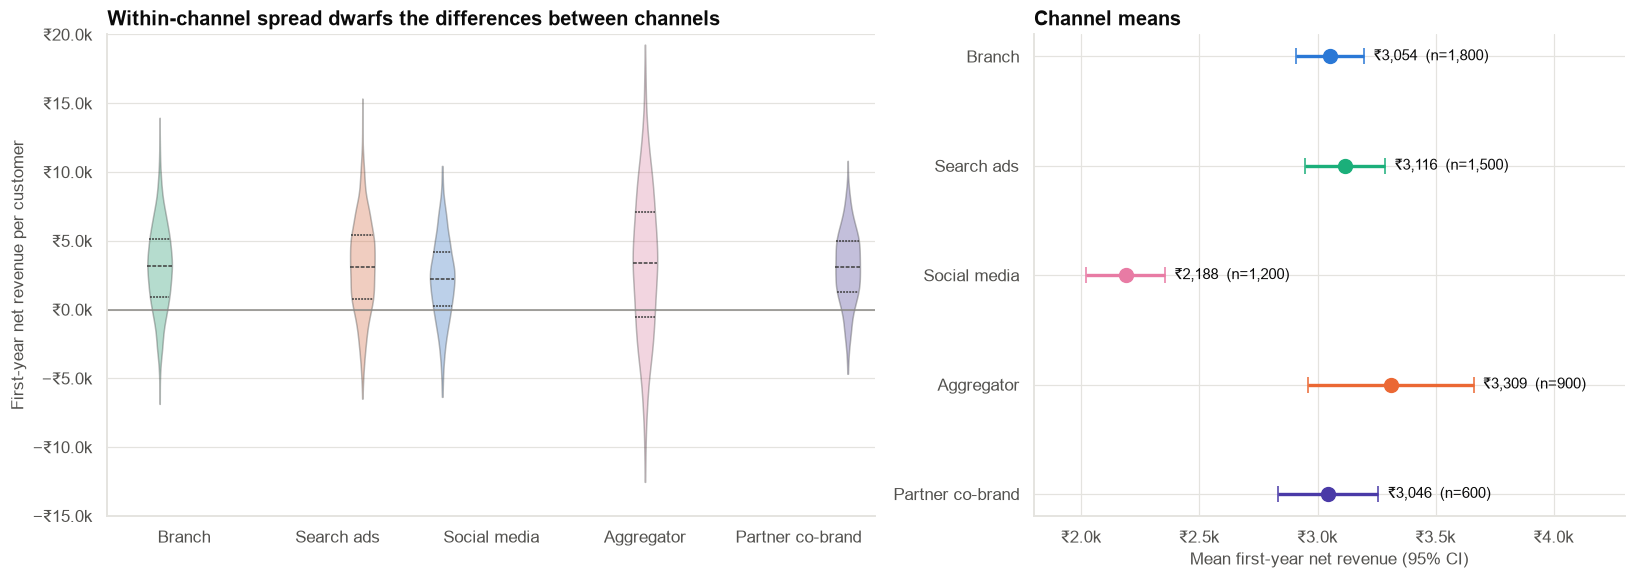

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
sns.violinplot(data=cust, x="channel", y=y, order=ORDER, ax=ax, inner="quartile", cut=0,
               palette=CH_COL, hue="channel", hue_order=ORDER, legend=False, linewidth=1)
for c in ax.collections:
    c.set_alpha(0.35)
ax.yaxis.set_major_formatter(kfmt)
ax.axhline(0, color=INK_MUTED, lw=1)
ax.set(xlabel="", ylabel="First-year net revenue per customer", title="Within-channel spread dwarfs the differences between channels")
ax.set_ylim(-15_000, 20_000)
ax = axes[1]
for i, ch in enumerate(ORDER):
    r = desc.loc[ch]
    ax.errorbar(r["mean"], i, xerr=[[r["mean"] - r["ci_low"]], [r["ci_high"] - r["mean"]]], fmt="o", ms=9, capsize=5, lw=2.2,
                color=CH_COL[ch])
    ax.text(r["ci_high"] + 40, i, f"₹{r['mean']:,.0f}  (n={int(r['n']):,})", va="center", fontsize=10)
ax.set_yticks(range(len(ORDER)), ORDER); ax.invert_yaxis()
ax.xaxis.set_major_formatter(kfmt)
ax.set(xlabel="Mean first-year net revenue (95% CI)", title="Channel means", xlim=(1_800, 4_300))
fig.tight_layout()
save_fig(fig, "fig01_revenue_by_channel", PATHS["figures"])
plt.show()

**Observation.** All channels overlap heavily: most of the variation is between customers, not between channels.
The confidence intervals separate Social media clearly from the others; Branch, Search ads and Partner co-brand overlap
almost entirely; the Aggregator's interval is wide (high variance) and overlaps Search ads.

## Section 7 — Method selection: why not ten t-tests?

Five channels give **10 pairs**. If each pair is tested at α = 0.05, the chance of at least one false alarm when
**nothing** differs is much more than 5%. Simulation:

In [5]:
sizes = desc["n"].astype(int).to_numpy()
sd_pool = np.sqrt(((desc["n"] - 1) * desc["sd"] ** 2).sum() / (desc["n"].sum() - len(desc)))
any_sig, anova_sig = 0, 0
n_sim = 2000
for _ in range(n_sim):
    groups = [rng.normal(3_000, sd_pool, n) for n in sizes]
    ps = [stats.ttest_ind(a, b).pvalue for a, b in combinations(groups, 2)]
    any_sig += min(ps) < 0.05
    anova_sig += stats.f_oneway(*groups).pvalue < 0.05
fwer = pd.DataFrame({"P(at least one 'significant' result)": [any_sig / n_sim, anova_sig / n_sim]},
                    index=["10 separate t-tests at α = 0.05", "one ANOVA F-test at α = 0.05"])
save_table(fwer, "false_alarm_simulation", PATHS["tables"])
fwer

,P(at least one 'significant' result)
10 separate t-tests at α = 0.05,0.2950
one ANOVA F-test at α = 0.05,0.0405


**Observation.** When all five channels truly have the same mean, running 10 t-tests produces at least one
"significant" difference in roughly **a quarter to a third** of studies; a single ANOVA keeps the false-alarm rate at
the intended 5%. (It is below the naive 1 − 0.95¹⁰ = 40% because the tests share groups and are correlated.)

**Method.**

| Step | Method | Why |
|---|---|---|
| 1. Is there any difference? | **One-way ANOVA** (or **Welch ANOVA** if variances differ) | One test for "all means equal" |
| 2. Which pairs? | **Tukey HSD** (equal variances) or **Games-Howell** (unequal) | Controls the family-wise error across all pairs |
| 3. How big? | η², ω², and mean differences in ₹ with CIs | Significance is not size |
| 4. Planned questions | **Contrasts** decided before looking (e.g. digital vs offline) | More power than all-pairs tests |
| 5. Confounding | **ANCOVA**: add income as a covariate | Separates channel from customer mix |

**ANOVA's idea in one line:** if the channel means differ, the variation **between** channel means will be large
relative to the variation **within** channels. F = (between-group mean square) / (within-group mean square).

## Section 8 — One-way ANOVA

In [6]:
m_anova = smf.ols(f"{y} ~ channel", cust).fit()
tbl = anova_lm(m_anova, typ=1)
ss_between, ss_within = tbl.loc["channel", "sum_sq"], tbl.loc["Residual", "sum_sq"]
ss_total = ss_between + ss_within
k, N = len(ORDER), len(cust)
ms_within = ss_within / (N - k)
eta2 = ss_between / ss_total
omega2 = (ss_between - (k - 1) * ms_within) / (ss_total + ms_within)
tbl["share of total SS (η² for channel)"] = tbl["sum_sq"] / ss_total
save_table(tbl, "anova_table", PATHS["tables"])
display(tbl)
print(f"F({k - 1}, {N - k}) = {tbl.loc['channel', 'F']:.1f}, p = {fmt_p(tbl.loc['channel', 'PR(>F)'])}")
print(f"η² = {eta2:.4f}  (share of variation explained by channel);  ω² = {omega2:.4f}  (less biased)")
f_scipy = stats.f_oneway(*[g[y].to_numpy() for _, g in cust.groupby("channel", observed=True)])
print(f"Check with scipy.stats.f_oneway: F = {f_scipy.statistic:.1f}  (identical: ANOVA is a regression on channel dummies)")

,df,sum_sq,mean_sq,F,PR(>F),share of total SS (η² for channel)
channel,4.0000,"878,158,207.0000","219,539,551.7500",17.6145,0.0000,0.0116
Residual,"5,995.0000","74,718,973,035.9333","12,463,548.4630",NaN,NaN,0.9884


F(4, 5995) = 17.6, p = < 0.001
η² = 0.0116  (share of variation explained by channel);  ω² = 0.0110  (less biased)
Check with scipy.stats.f_oneway: F = 17.6  (identical: ANOVA is a regression on channel dummies)


**Observation.** F is large (p < 0.001): the channel means are not all equal. But channel explains only about **1%** of
the variation in first-year revenue (η² ≈ ω² ≈ 0.01).

**Interpretation.**
- **Statistically**, the evidence that channels differ is overwhelming, because 6,000 customers give a lot of power.
- **Practically**, knowing a customer's channel tells you little about that customer's revenue: individual customers
  vary far more than channel averages. That does **not** make the differences unimportant for budgeting: a ₹900
  difference per customer across thousands of customers is real money (Section 13).
- Conventional labels (η² ≈ 0.01 small, 0.06 medium, 0.14 large) are rough guides; judge size in ₹.

**ANOVA = regression.** The F-test above is exactly the regression F-test for "all channel dummies are zero". The
same model extends naturally to covariates (Section 12).

## Section 9 — Checking the assumptions

,statistic,p_value
Levene (mean-centred),158.8002,0.0000
Brown-Forsythe (median-centred),158.5597,0.0000
residual skewness,-0.0264,NaN
residual excess kurtosis,0.7019,NaN


SD ratio, largest / smallest group: 2.03


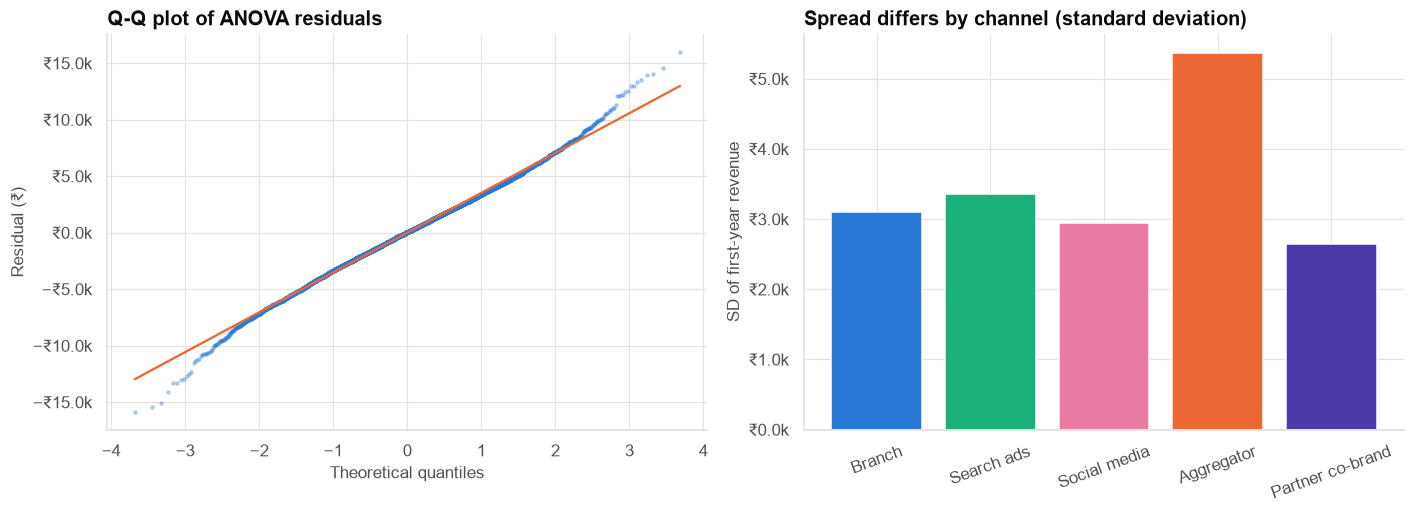

In [7]:
groups = [g[y].to_numpy() for _, g in cust.groupby("channel", observed=True)]
lev = stats.levene(*groups, center="mean")
bf = stats.levene(*groups, center="median")
resid = m_anova.resid
assump = pd.DataFrame({"statistic": [lev.statistic, bf.statistic, stats.skew(resid), stats.kurtosis(resid)],
                       "p_value": [lev.pvalue, bf.pvalue, np.nan, np.nan]},
                      index=["Levene (mean-centred)", "Brown-Forsythe (median-centred)", "residual skewness", "residual excess kurtosis"])
save_table(assump, "assumption_checks", PATHS["tables"])
display(assump)
print("SD ratio, largest / smallest group:", round(desc["sd"].max() / desc["sd"].min(), 2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
stats.probplot(resid, dist="norm", plot=axes[0])
axes[0].get_lines()[0].set(markersize=2, alpha=0.3, color=PRIMARY); axes[0].get_lines()[1].set(color=HIGHLIGHT)
axes[0].set(title="Q-Q plot of ANOVA residuals", xlabel="Theoretical quantiles", ylabel="Residual (₹)")
axes[0].yaxis.set_major_formatter(kfmt)
axes[1].bar(ORDER, desc.loc[ORDER, "sd"], color=[CH_COL[c] for c in ORDER])
axes[1].yaxis.set_major_formatter(kfmt)
axes[1].set(title="Spread differs by channel (standard deviation)", ylabel="SD of first-year revenue")
axes[1].tick_params(axis="x", rotation=20)
fig.tight_layout()
save_fig(fig, "fig02_assumptions", PATHS["figures"])
plt.show()

**Observation.**
- **Equal variances: violated.** Levene and Brown-Forsythe tests reject strongly; the aggregator's SD is about twice
  that of the partner channel.
- **Normality:** residuals have heavier tails than normal (Q-Q plot bends at both ends). With hundreds of customers per
  group, the **central limit theorem** (Case 01) makes the F-test and t-intervals robust to this.
- **Independence:** customers are distinct; reasonable.

**Why unequal variances matter here.** The classic F-test pools all groups' variances. When variances **and** group
sizes differ, the classic test's false-alarm rate can be too high or too low, depending on whether the
large-variance group is small or large. Here the high-variance aggregator is a smaller group, which can make the
classic F-test **too liberal**. The fix is **Welch's ANOVA**, which does not assume equal variances.

## Section 10 — Welch ANOVA

In [8]:
welch = anova_oneway(cust[y], cust["channel"], use_var="unequal", welch_correction=True)
classic = anova_oneway(cust[y], cust["channel"], use_var="equal")
cmp = pd.DataFrame({"F": [classic.statistic, welch.statistic], "df (num, denom)": [f"{classic.df_num:.0f}, {classic.df_denom:.0f}",
                                                                                f"{welch.df_num:.0f}, {welch.df_denom:.0f}"],
                    "p_value": [classic.pvalue, welch.pvalue]}, index=["Classic ANOVA (equal variances)", "Welch ANOVA (unequal variances)"])
save_table(cmp, "classic_vs_welch", PATHS["tables"])
cmp

,F,"df (num, denom)",p_value
Classic ANOVA (equal variances),17.6145,"4, 5995",0.0000
Welch ANOVA (unequal variances),21.8409,"4, 2401",0.0000


**Observation.** Both versions reject "all channel means are equal" decisively (p < 0.001). Welch's version uses far
fewer denominator degrees of freedom, reflecting the unequal variances.

**Rule.** Use **Welch's ANOVA by default** when group sizes or variances differ: it loses almost nothing when variances
are equal and protects you when they are not (the same advice as Welch's t-test in Case 02).

## Section 11 — Which channels differ? Post-hoc tests

In [9]:
tukey = pairwise_tukeyhsd(cust[y], cust["channel"].astype(str), alpha=0.05)
tk = pd.DataFrame(tukey.summary().data[1:], columns=tukey.summary().data[0])

def games_howell(df, group, value, alpha=0.05):
    g = df.groupby(group, observed=True)[value].agg(["mean", "var", "size"])
    k_ = len(g)
    rows = []
    for a, b in combinations(g.index, 2):
        ma, va, na = g.loc[a]; mb, vb, nb_ = g.loc[b]
        diff = mb - ma
        se = np.sqrt(va / na + vb / nb_)
        dfw = (va / na + vb / nb_) ** 2 / ((va / na) ** 2 / (na - 1) + (vb / nb_) ** 2 / (nb_ - 1))
        q = abs(diff) / se * np.sqrt(2)
        p = stats.studentized_range.sf(q, k_, dfw)
        qcrit = stats.studentized_range.ppf(1 - alpha, k_, dfw) / np.sqrt(2)
        rows.append({"group1": a, "group2": b, "mean diff (2 − 1)": diff, "ci_low": diff - qcrit * se,
                     "ci_high": diff + qcrit * se, "p_adj": p, "reject H0": p < alpha})
    return pd.DataFrame(rows)

gh = games_howell(cust, "channel", y)
post = gh.merge(tk.rename(columns={"group1": "t1", "group2": "t2", "p-adj": "Tukey p_adj", "reject": "Tukey reject"})[["t1", "t2", "Tukey p_adj", "Tukey reject"]],
                left_on=["group1", "group2"], right_on=["t1", "t2"], how="left")
# Tukey's table orders pairs alphabetically; align where the order differs.
miss = post["Tukey p_adj"].isna()
if miss.any():
    alt = tk.rename(columns={"group1": "t2", "group2": "t1", "p-adj": "Tukey p_adj", "reject": "Tukey reject"})[["t1", "t2", "Tukey p_adj", "Tukey reject"]]
    post.loc[miss, ["Tukey p_adj", "Tukey reject"]] = post.loc[miss, ["group1", "group2"]].merge(
        alt, left_on=["group1", "group2"], right_on=["t1", "t2"], how="left")[["Tukey p_adj", "Tukey reject"]].to_numpy()
post = post.drop(columns=["t1", "t2"])
save_table(post.set_index(["group1", "group2"]), "posthoc_pairs", PATHS["tables"])
post

,group1,group2,mean diff (2 − 1),ci_low,ci_high,p_adj,reject H0,Tukey p_adj,Tukey reject
0,Branch,Search ads,61.8956,-248.0011,371.7922,0.9825,False,0.9872,False
1,Branch,Social media,-866.1611,"-1,172.1947",-560.1275,0.0000,True,0.0000,True
2,Branch,Aggregator,255.6333,-272.0518,783.3184,0.6766,False,0.3891,False
3,Branch,Partner co-brand,-8.1111,-364.0958,347.8736,1.0000,False,1.0000,False
4,Search ads,Social media,-928.0567,"-1,259.8614",-596.2519,0.0000,True,0.0000,True
5,Search ads,Aggregator,193.7378,-349.2502,736.7258,0.8667,False,0.6903,False
6,Search ads,Partner co-brand,-70.0067,-448.3294,308.3160,0.9868,False,0.9940,False
7,Social media,Aggregator,"1,121.7944",581.0059,"1,662.5830",0.0000,True,0.0000,True
8,Social media,Partner co-brand,858.0500,482.8857,"1,233.2143",0.0000,True,0.0000,True
9,Aggregator,Partner co-brand,-263.7444,-834.0886,306.5997,0.7140,False,0.6164,False


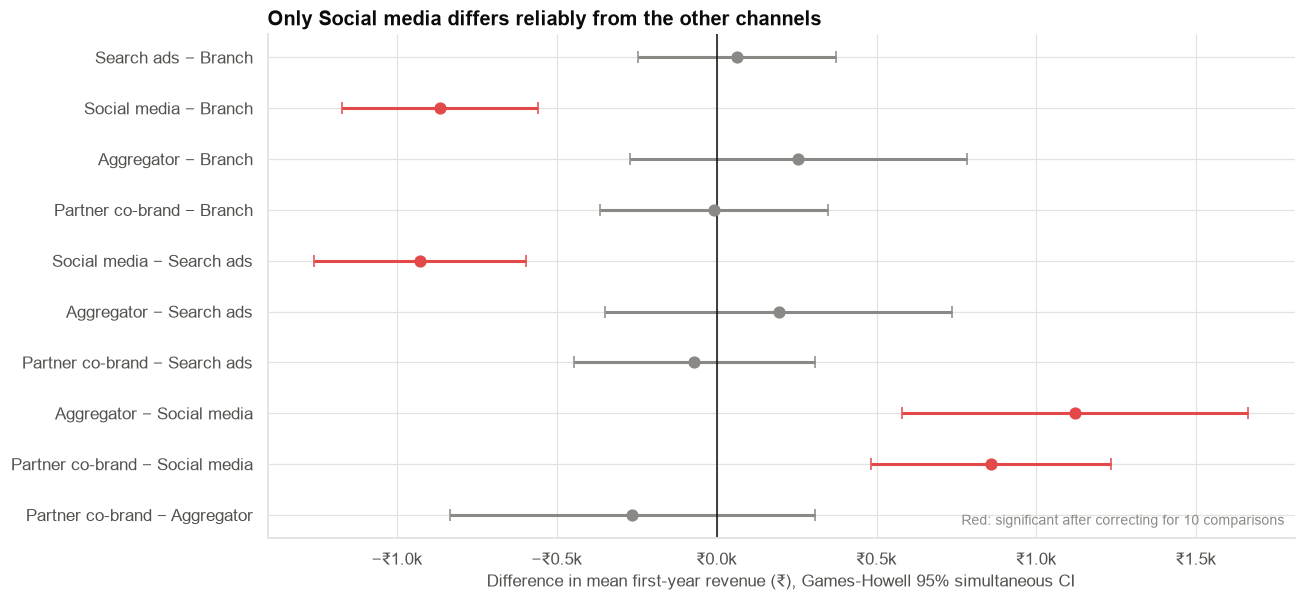

In [10]:
fig, ax = plt.subplots(figsize=(12, 5.6))
lab = [f"{b} − {a}" for a, b in zip(post["group1"], post["group2"])]
yy = np.arange(len(post))[::-1]
for yi, (_, r), l in zip(yy, post.iterrows(), lab):
    col = COLORS["red"] if r["reject H0"] else INK_MUTED
    ax.errorbar(r["mean diff (2 − 1)"], yi, xerr=[[r["mean diff (2 − 1)"] - r["ci_low"]], [r["ci_high"] - r["mean diff (2 − 1)"]]],
                fmt="o", color=col, capsize=4, ms=7, lw=2)
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(yy, lab)
ax.xaxis.set_major_formatter(kfmt)
ax.set(xlabel="Difference in mean first-year revenue (₹), Games-Howell 95% simultaneous CI",
       title="Only Social media differs reliably from the other channels")
add_note(ax, "Red: significant after correcting for 10 comparisons", "lower right")
fig.tight_layout()
save_fig(fig, "fig03_posthoc", PATHS["figures"])
plt.show()

**Observation.** Both Tukey HSD and Games-Howell give the same verdicts here: **Social media is lower than every other
channel** (by about ₹850–1,100 per customer); no other pair differs significantly. In particular, the **Aggregator is
not reliably better** than Branch, Search ads or Partner co-brand: its higher average comes with very high variance.

**Tukey vs Games-Howell.** Tukey HSD assumes equal variances; Games-Howell uses each pair's own variances and Welch
degrees of freedom. With unequal variances, Games-Howell is the safer choice: its intervals are wider for pairs
involving the aggregator and narrower for low-variance pairs.

**Simultaneous intervals.** These CIs are wider than ordinary two-group CIs because they are built to cover **all 10
differences at once** with 95% confidence.

### 11.1 A planned contrast: digital vs offline

In [11]:
# Decided before looking at the data: do digital channels (search, social, aggregator) differ from the others?
digital = cust["channel"].isin(["Search ads", "Social media", "Aggregator"])
w = pd.Series({"Branch": -1 / 2, "Partner co-brand": -1 / 2, "Search ads": 1 / 3, "Social media": 1 / 3, "Aggregator": 1 / 3})
est = (w * desc["mean"]).sum()
se_c = np.sqrt((w ** 2 * desc["sd"] ** 2 / desc["n"]).sum())
df_c = (w ** 2 * desc["sd"] ** 2 / desc["n"]).sum() ** 2 / ((w ** 2 * desc["sd"] ** 2 / desc["n"]) ** 2 / (desc["n"] - 1)).sum()
t_c = est / se_c
contrast = pd.DataFrame({"estimate (₹)": [est], "ci_low": [est - stats.t.ppf(0.975, df_c) * se_c],
                         "ci_high": [est + stats.t.ppf(0.975, df_c) * se_c], "t": [t_c], "df": [df_c],
                         "p_value": [2 * stats.t.sf(abs(t_c), df_c)]}, index=["average of digital − average of offline/partner"])
save_table(contrast, "planned_contrast", PATHS["tables"])
contrast

,estimate (₹),ci_low,ci_high,t,df,p_value
average of digital − average of offline/partner,-178.8219,-369.3135,11.6698,-1.8406,"2,953.6605",0.0658


**Observation.** On average, the three digital channels bring customers worth about ₹180 less in their first year than
branch and partner channels, but the 95% CI (about −₹370 to +₹10) includes zero (p ≈ 0.07). There is no clear
"digital vs offline" gap: social media's deficit is largely offset by search ads and the aggregator.

**Interpretation.** A **planned contrast** answers one pre-specified question with a single test, so it needs no
multiple-comparison correction and has more power than the all-pairs tests. It must be chosen **before** looking at the
results; picking contrasts after seeing the data is just multiple testing in disguise (Case 19).

## Section 12 — Is it the channel or the customers? ANCOVA

In [12]:
m_ancova = smf.ols(f"{y} ~ channel + log_income", cust).fit(cov_type="HC3")
m_raw = smf.ols(f"{y} ~ channel", cust).fit(cov_type="HC3")
rows = []
for ch in ORDER[1:]:
    t = f"channel[T.{ch}]"
    rows.append({"channel": ch, "raw difference vs Branch (₹)": m_raw.params[t], "raw p": m_raw.pvalues[t],
                 "at the same income (₹)": m_ancova.params[t], "ci_low": m_ancova.conf_int().loc[t, 0],
                 "ci_high": m_ancova.conf_int().loc[t, 1], "adjusted p": m_ancova.pvalues[t]})
anc = pd.DataFrame(rows).set_index("channel")
save_table(anc, "ancova_channel_effects", PATHS["tables"])
display(anc)
f_block = m_ancova.f_test(" = 0, ".join([f"channel[T.{c}]" for c in ORDER[1:]]) + " = 0")
print(f"Income effect: ₹{m_ancova.params['log_income']:,.0f} per unit of log income "
      f"(≈ ₹{m_ancova.params['log_income'] * np.log(1.1):,.0f} per 10% more income)")
print(f"Channels jointly, at the same income (robust Wald F): F = {float(np.squeeze(f_block.fvalue)):.1f}, p = {fmt_p(float(f_block.pvalue))}")

,raw difference vs Branch (₹),raw p,at the same income (₹),ci_low,ci_high,adjusted p
channel,,,,,,
Search ads,61.8956,0.5858,-66.6795,-273.9249,140.5659,0.5283
Social media,-866.1611,0.0000,-226.5916,-433.4687,-19.7145,0.0318
Aggregator,255.6333,0.1859,-659.2044,"-1,030.7930",-287.6157,0.0005
Partner co-brand,-8.1111,0.9504,287.9048,55.6582,520.1515,0.0151


Income effect: ₹2,654 per unit of log income (≈ ₹253 per 10% more income)
Channels jointly, at the same income (robust Wald F): F = 7.6, p = < 0.001


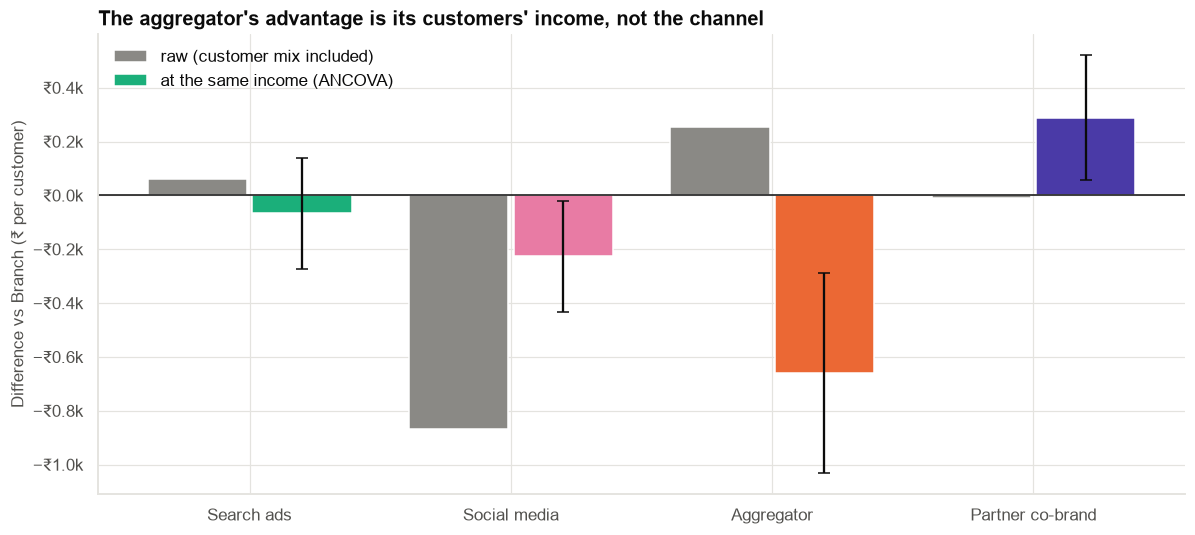

In [13]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(ORDER) - 1)
ax.bar(x - 0.2, anc["raw difference vs Branch (₹)"], width=0.38, color=INK_MUTED, label="raw (customer mix included)")
ax.bar(x + 0.2, anc["at the same income (₹)"], width=0.38, color=[CH_COL[c] for c in ORDER[1:]], label="at the same income (ANCOVA)")
ax.errorbar(x + 0.2, anc["at the same income (₹)"], yerr=[anc["at the same income (₹)"] - anc["ci_low"], anc["ci_high"] - anc["at the same income (₹)"]],
            fmt="none", color=INK, capsize=4)
ax.axhline(0, color=INK, lw=1)
ax.set_xticks(x, ORDER[1:])
ax.yaxis.set_major_formatter(kfmt)
ax.set(ylabel="Difference vs Branch (₹ per customer)", title="The aggregator's advantage is its customers' income, not the channel")
ax.legend(frameon=False)
fig.tight_layout()
save_fig(fig, "fig04_ancova", PATHS["figures"])
plt.show()

**Observation.** Raw, the aggregator is about ₹250 **above** Branch (not significant). At the same income, it is about
₹650 **below** Branch (95% CI about −₹1,030 to −₹290). Social media's gap shrinks from about −₹870 to about −₹230
(still significant, p ≈ 0.03): most of its low value is that it attracts lower-income customers. Partner co-brand moves
up to about **+₹290** (p ≈ 0.02): at the same income, its customers are worth more than branch customers.

**Interpretation.** The aggregator delivers **high-income customers who are worth less than other high-income
customers** (rate-chasers, more defaults). The channel's raw advantage is **customer mix**, not channel quality
(confounding by income, Case 08).

**Which comparison should the business use?** Both, for different questions:
- *"What do we get per customer from each channel?"*: the **raw** comparison (the mix is part of what the channel
  delivers).
- *"Is the channel itself good, or could we get the same customers more cheaply elsewhere?"*: the **adjusted**
  comparison. If high-income customers can be reached through search or the partner, they would be worth more there.

## Section 13 — Where should the budget go? Value net of acquisition cost

In [14]:
boot = {ch: [] for ch in ORDER}
for _ in range(4000):
    for ch in ORDER:
        v = cust.loc[cust["channel"] == ch, y].to_numpy()
        boot[ch].append(rng.choice(v, len(v)).mean())
econ = pd.DataFrame({"mean value (₹)": desc.loc[ORDER, "mean"], "cost per acquisition (₹)": costs.loc[ORDER]})
econ["net value per customer (₹)"] = econ["mean value (₹)"] - econ["cost per acquisition (₹)"]
econ["net ci_low"] = [np.percentile(np.array(boot[c]) - costs[c], 2.5) for c in ORDER]
econ["net ci_high"] = [np.percentile(np.array(boot[c]) - costs[c], 97.5) for c in ORDER]
econ["value per ₹ of CAC"] = econ["mean value (₹)"] / econ["cost per acquisition (₹)"]
econ["value per ₹ ci_low"] = [np.percentile(np.array(boot[c]) / costs[c], 2.5) for c in ORDER]
econ["value per ₹ ci_high"] = [np.percentile(np.array(boot[c]) / costs[c], 97.5) for c in ORDER]
econ["net value per ₹1 lakh of budget (₹)"] = 1e5 / econ["cost per acquisition (₹)"] * econ["net value per customer (₹)"]
save_table(econ, "channel_economics", PATHS["tables"])
econ

,mean value (₹),cost per acquisition (₹),net value per customer (₹),net ci_low,net ci_high,value per ₹ of CAC,value per ₹ ci_low,value per ₹ ci_high,net value per ₹1 lakh of budget (₹)
channel,,,,,,,,,
Branch,"3,053.7778",2200,853.7778,713.4486,992.8111,1.3881,1.3243,1.4513,"38,808.0808"
Search ads,"3,115.6733",1800,"1,315.6733","1,147.7260","1,490.2868",1.7309,1.6376,1.8279,"73,092.9630"
Social media,"2,187.6167",1100,"1,087.6167",915.8902,"1,252.9267",1.9887,1.8326,2.1390,"98,874.2424"
Aggregator,"3,309.4111",2900,409.4111,57.8469,769.8450,1.1412,1.0199,1.2655,"14,117.6245"
Partner co-brand,"3,045.6667",900,"2,145.6667","1,933.4683","2,360.5700",3.3841,3.1483,3.6229,"238,407.4074"


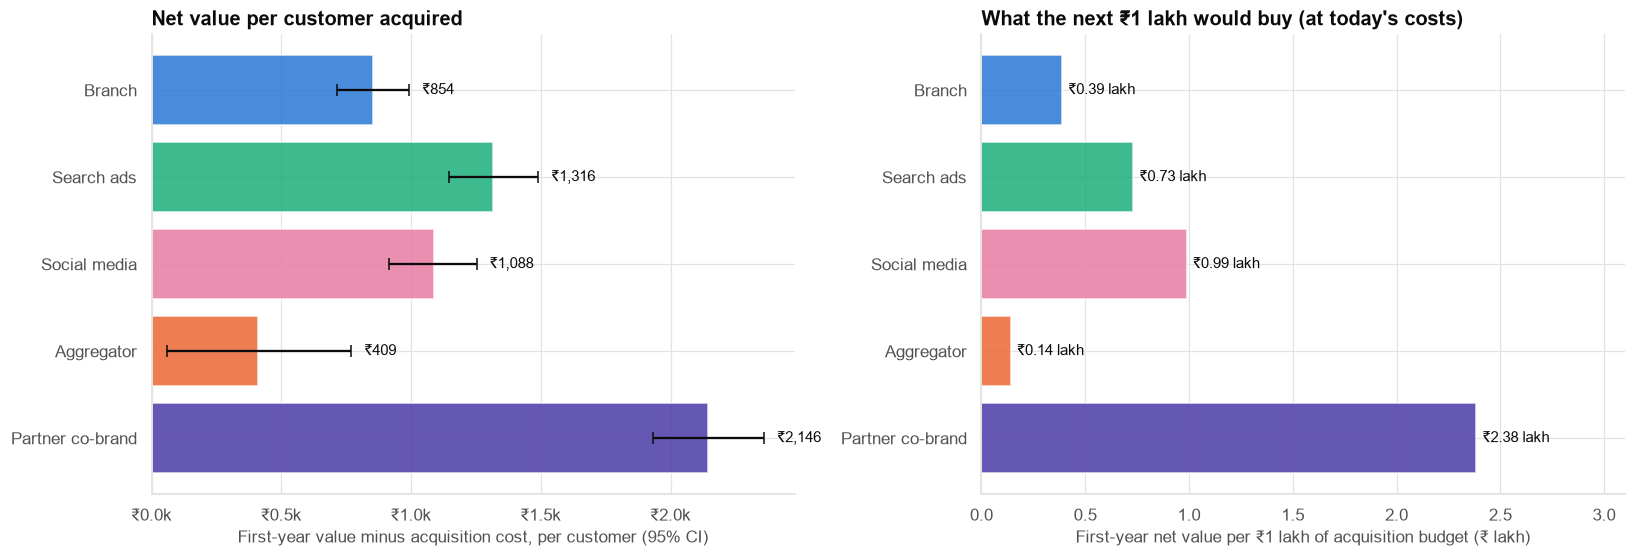

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
ax = axes[0]
for i, ch in enumerate(ORDER):
    r = econ.loc[ch]
    ax.barh(i, r["net value per customer (₹)"], color=CH_COL[ch], alpha=0.85)
    ax.errorbar(r["net value per customer (₹)"], i, xerr=[[r["net value per customer (₹)"] - r["net ci_low"]],
                                                         [r["net ci_high"] - r["net value per customer (₹)"]]], fmt="none", color=INK, capsize=4)
    ax.text(r["net ci_high"] + 50, i, f"₹{r['net value per customer (₹)']:,.0f}", va="center", fontsize=10)
ax.set_yticks(range(len(ORDER)), ORDER); ax.invert_yaxis()
ax.xaxis.set_major_formatter(kfmt)
ax.set(xlabel="First-year value minus acquisition cost, per customer (95% CI)", title="Net value per customer acquired")
ax = axes[1]
vals = econ["net value per ₹1 lakh of budget (₹)"] / 1e5
ax.barh(range(len(ORDER)), vals, color=[CH_COL[c] for c in ORDER], alpha=0.85)
for i, v in enumerate(vals):
    ax.text(v + 0.03, i, f"₹{v:,.2f} lakh", va="center", fontsize=10)
ax.set_yticks(range(len(ORDER)), ORDER); ax.invert_yaxis()
ax.set(xlabel="First-year net value per ₹1 lakh of acquisition budget (₹ lakh)", title="What the next ₹1 lakh would buy (at today's costs)",
       xlim=(0, vals.max() * 1.3))
fig.tight_layout()
save_fig(fig, "fig05_channel_economics", PATHS["figures"])
plt.show()

**Observation.**
- Net of acquisition cost, the **Partner co-brand** delivers by far the most value per customer (about ₹2,150) and
  per rupee of budget; **Search ads** and **Social media** come next.
- The **Aggregator**, the "most valuable" channel on raw revenue, is the **worst** once its high cost per acquisition
  (₹2,900) is subtracted: about ₹400 net per customer, with a CI reaching close to zero.
- **Social media**, the channel Marketing wanted to cut, delivers more net value per rupee than Branch or the
  aggregator, because it is cheap.

**Interpretation.** "Most valuable customers" and "best use of the budget" are different questions. Revenue per
customer ignores what the customer cost to acquire.

**Caveats.**
- These are **average** costs and values. The decision depends on **marginal** returns: doubling the aggregator or
  partner budget may bring in worse or more expensive customers (diminishing returns), and the partner channel may have
  limited capacity.
- First-year value is not lifetime value; channels may differ in retention (Case 11, Case 26).
- Channel performance was observed, not randomised. A **budget-shift test** (e.g. raise spend in some regions or
  weeks and not others) would measure marginal returns directly (Case 04, Case 21).

## Section 14 — Decision framework: comparing several groups

| Situation | Use | Then |
|---|---|---|
| 3+ groups, roughly normal (or large n), **equal** variances | One-way ANOVA | Tukey HSD for all pairs |
| 3+ groups, **unequal variances or sizes** | **Welch ANOVA** | **Games-Howell** |
| Strongly skewed / ordinal outcome, small groups, outliers | **Kruskal-Wallis** (Case 15) | Dunn's test with Holm correction |
| Specific comparisons planned in advance | **Contrasts** | No all-pairs correction needed (correct for the number of planned contrasts) |
| Groups differ in a confounder | **ANCOVA** / regression with covariates | Report raw and adjusted |
| Two factors (channel × product) | Two-way ANOVA with interaction | Interpret interaction first |
| Same customers measured repeatedly | Repeated-measures ANOVA / mixed model | – |
| ANOVA significant but η² tiny | Real but small differences | Judge in ₹ × volume, not by p |
| ANOVA not significant | No evidence of differences | Check power/CI width before concluding "no difference" |
| Post-hoc finds nothing although ANOVA is significant | Difference spread across several groups, or only in a contrast | Look at contrasts and CIs |

## Section 15 — Results

In [16]:
best = econ["net value per customer (₹)"].idxmax()
summary = pd.DataFrame({"Value": [
    f"Aggregator ₹{desc.loc['Aggregator', 'mean']:,.0f} (highest) … Social media ₹{desc.loc['Social media', 'mean']:,.0f} (lowest)",
    f"F = {tbl.loc['channel', 'F']:.1f} (classic), {welch.statistic:.1f} (Welch); p < 0.001 for both",
    f"η² = {eta2:.3f}, ω² = {omega2:.3f}: channel explains about 1% of customer-level variation",
    f"Levene/Brown-Forsythe p < 0.001; SD ratio {desc['sd'].max() / desc['sd'].min():.1f}",
    "Social media lower than every other channel; no other pair differs (Tukey and Games-Howell agree)",
    f"digital − offline/partner ≈ −₹{abs(contrast.iloc[0, 0]):,.0f} (p = {fmt_p(contrast.iloc[0]['p_value'])}; CI includes 0)",
    f"Aggregator vs Branch: raw +₹{anc.loc['Aggregator', 'raw difference vs Branch (₹)']:,.0f} → same income −₹{abs(anc.loc['Aggregator', 'at the same income (₹)']):,.0f}",
    f"best: {best} ₹{econ.loc[best, 'net value per customer (₹)']:,.0f}/customer; worst: Aggregator ₹{econ.loc['Aggregator', 'net value per customer (₹)']:,.0f}",
]}, index=["Mean first-year revenue", "ANOVA", "Effect size", "Equal variances?", "Post-hoc", "Planned contrast",
           "ANCOVA", "Net of acquisition cost"])
save_table(summary, "results_summary", PATHS["tables"])
summary

,Value
Mean first-year revenue,"Aggregator ₹3,309 (highest) … Social media ₹2,..."
ANOVA,"F = 17.6 (classic), 21.8 (Welch); p < 0.001 fo..."
Effect size,"η² = 0.012, ω² = 0.011: channel explains about..."
Equal variances?,Levene/Brown-Forsythe p < 0.001; SD ratio 2.0
Post-hoc,Social media lower than every other channel; n...
Planned contrast,digital − offline/partner ≈ −₹179 (p = 0.066; ...
ANCOVA,Aggregator vs Branch: raw +₹256 → same income ...
Net of acquisition cost,"best: Partner co-brand ₹2,146/customer; worst:..."


## Section 16 — Interpretation

- **The channels do differ**, but the differences are small relative to customer-to-customer variation (η² ≈ 1%).
- **Only social media is reliably different** (lower) in revenue per customer. The aggregator's lead over the other
  channels is not statistically reliable.
- **The aggregator's high revenue comes from high-income customers**, who are worth more elsewhere; at the same income
  it is the weakest channel.
- **Net of acquisition cost**, the partner co-brand is the best channel and the aggregator the worst. The proposal
  (double the aggregator, cut social media) is the opposite of what the data support.

## Section 17 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "Average first-year revenue differs across channels (Welch ANOVA p < 0.001)." | "Every channel is different from every other." |
| "Social-media customers bring about ₹850–1,100 less revenue in year one than other channels' customers." | "The aggregator brings more valuable customers" (not reliably; and not at the same income). |
| "After acquisition costs, the partner channel delivered the most value per customer last year." | "Moving budget to the partner channel will deliver ₹2,150 per extra customer" (marginal returns unknown). |
| "Channel explains about 1% of the variation in customer revenue." | "Channel doesn't matter" (₹ differences × volume are material). |

## Section 18 — Business interpretation

- **Do not double the aggregator**: it is the most expensive channel and, once income is considered, the weakest.
- **Do not cut social media** on revenue alone: it is cheap and returns more per rupee than branch or aggregator.
- **Grow the partner co-brand** as far as its capacity allows, and test whether high-income customers can be reached
  more cheaply through search or partners.

## Section 19 — Limitations

- Observational comparison; channel performance was not randomised.
- Average, not marginal, cost and value.
- First-year value only; retention may differ by channel.
- Synthetic data.

## Section 20 — Final recommendation

> **Reject the proposal to double the aggregator and cut social media.** Shift budget towards the **partner co-brand**
> (highest net value per customer and per rupee), keep **social media** (cheap, positive net value), and run a
> **controlled budget test** (regions or weeks) before any large reallocation, to measure marginal returns.

## Section 21 — What would I do next?

1. Design a **geo budget-shift experiment** to estimate marginal value per rupee by channel.
2. Extend to **lifetime value**: add retention and credit losses beyond year one (Cases 11, 26).
3. Add **product** as a second factor (two-way ANOVA: channel × card type) to see whether channels suit different cards.
4. Continue to **Case 15** for the non-parametric alternatives (Kruskal-Wallis, Dunn) when distributions are skewed
   and groups small.